# IS507 Heart Failure Death Prediction
**Goal:** predict whether a heart failure patient dies during follow-up (up to ~10 months), using Logistic Regression, Random Forest, and XGBoost.

**Plan:** load data → check data → split → baseline → models → tune → test fake (synthetic) data → feature importance → one final test.

## Step 1: Import libraries
**Must run this cell first.** Every cell below depends on these libraries.

In [8]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     StratifiedKFold, GridSearchCV, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42          # keeps results the same every run
pd.set_option("display.max_colwidth", None)

## Step 2: Load the data
Loading the UCI Heart Failure dataset into a table called `df`. Each row is one patient.
The last column, `DEATH_EVENT`, is what we want to predict (1 = died, 0 = survived).

In [ ]:
df = pd.read_csv('data/heart_failure_clinical_records_dataset.csv')
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


## Step 3: Check the data
Checking for missing values, duplicate rows, and how many patients survived vs died.
**Why it matters:** the data is lopsided (more survivors than deaths), and `time` only goes up to 285 days.
That is why we predict death *during follow-up* and not 1, 2, or 3 year survival.

In [11]:
print("Shape (rows, columns):", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nDeath event counts:")
print(df['DEATH_EVENT'].value_counts())
print("\nDeath event percentages:")
print((df['DEATH_EVENT'].value_counts(normalize=True) * 100).round(1))
print("\nFollow-up time (days):")
print(df['time'].describe().round(1))

Shape (rows, columns): (299, 13)
Missing values: 0
Duplicate rows: 0

Death event counts:
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64

Death event percentages:
DEATH_EVENT
0    67.9
1    32.1
Name: proportion, dtype: float64

Follow-up time (days):
count    299.0
mean     130.3
std       77.6
min        4.0
25%       73.0
50%      115.0
75%      203.0
max      285.0
Name: time, dtype: float64


## Step 4: Describe the variables
Summary numbers and charts for the clinical variables.
Number columns get mean, median, min, max, and standard deviation. Yes/no columns get counts and percentages.

,mean,median,min,max,std
age,60.83,60.0,40.0,95.0,11.89
creatinine_phosphokinase,581.84,250.0,23.0,7861.0,970.29
ejection_fraction,38.08,38.0,14.0,80.0,11.83
platelets,263358.03,262000.0,25100.0,850000.0,97804.24
serum_creatinine,1.39,1.1,0.5,9.4,1.03
serum_sodium,136.63,137.0,113.0,148.0,4.41
time,130.26,115.0,4.0,285.0,77.61


,count_0,count_1,percent_1
anaemia,170,129,43.1
diabetes,174,125,41.8
high_blood_pressure,194,105,35.1
sex,105,194,64.9
smoking,203,96,32.1
DEATH_EVENT,203,96,32.1


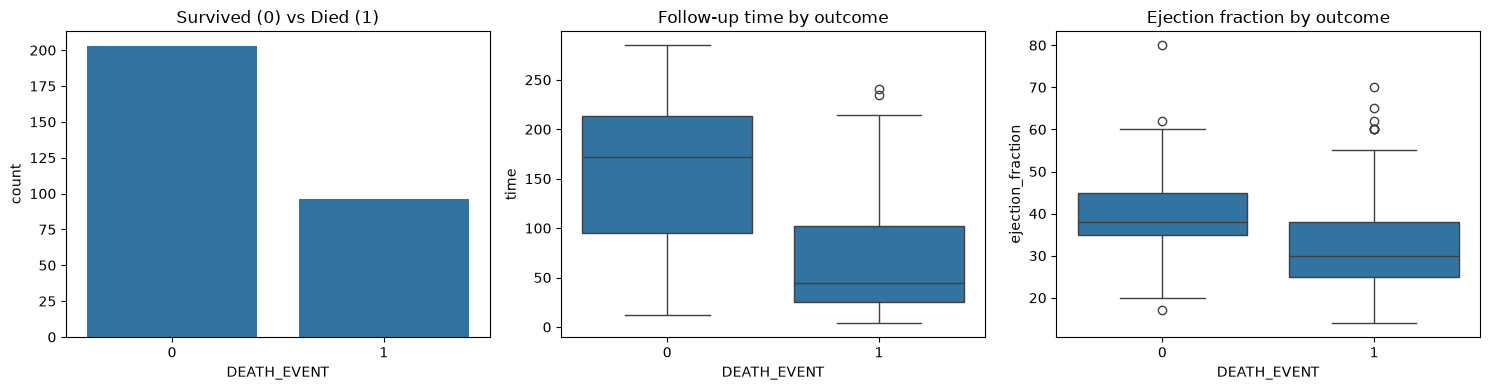

In [12]:
continuous = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets',
              'serum_creatinine', 'serum_sodium', 'time']
binary = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT']

display(df[continuous].agg(['mean', 'median', 'min', 'max', 'std']).T.round(2))

counts = pd.DataFrame({c: df[c].value_counts() for c in binary}).T
counts.columns = ['count_0', 'count_1']
counts['percent_1'] = (counts['count_1'] / len(df) * 100).round(1)
display(counts)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x='DEATH_EVENT', data=df, ax=ax[0])
ax[0].set_title('Survived (0) vs Died (1)')
sns.boxplot(x='DEATH_EVENT', y='time', data=df, ax=ax[1])
ax[1].set_title('Follow-up time by outcome')
sns.boxplot(x='DEATH_EVENT', y='ejection_fraction', data=df, ax=ax[2])
ax[2].set_title('Ejection fraction by outcome')
plt.tight_layout()
plt.show()

## Step 5: Split the data (train and test)
80% of the real patients go to training (239) and 20% are locked away as a test set (60).
The split keeps the same survive/die ratio in both parts. **The test set is not touched until the very last step.**

I also make two feature lists: one with `time` and one without it.
`time` is the follow-up length, which ends when a patient dies, so a doctor would not know it in advance.

In [13]:
X = df.drop(columns='DEATH_EVENT')
y = df['DEATH_EVENT']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Training patients:", len(X_train), "| Test patients:", len(X_test))
print("Train deaths:", y_train.sum(), "| Test deaths:", y_test.sum())
print("Rows shared by train and test (should be 0):", len(X_train.merge(X_test, how='inner')))

ALL_FEATURES = list(X.columns)
NO_TIME = [c for c in ALL_FEATURES if c != 'time']
FEATURE_SETS = {'with time': ALL_FEATURES, 'without time': NO_TIME}

Training patients: 239 | Test patients: 60
Train deaths: 77 | Test deaths: 19
Rows shared by train and test (should be 0): 0


## Step 6: Baseline (the score to beat)
The baseline guesses "survived" for every patient. It scores about 68% accuracy but catches **zero** deaths.
So 80% accuracy is only about 12 points above guessing, and accuracy alone is not enough.

**Testing method:** repeated 5-fold cross-validation on the training set. The data is split into 5 parts, 
each part takes a turn being the quiz, and this repeats 10 times. We report the average ± standard deviation (how much it jumps around).

In [14]:
SCORING = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)

def run_cv(model, cols, cv_obj=cv):
    res = cross_validate(model, X_train[cols], y_train, cv=cv_obj, scoring=SCORING, n_jobs=-1)
    return {s: (res[f'test_{s}'].mean(), res[f'test_{s}'].std()) for s in SCORING}

def to_table(records):
    out = []
    for r in records:
        row = {k: v for k, v in r.items() if k not in SCORING}
        for s in SCORING:
            m, sd = r[s]
            row[s] = f"{m:.3f} ± {sd:.3f}"
        out.append(row)
    return pd.DataFrame(out)

baseline = run_cv(DummyClassifier(strategy='most_frequent'), ALL_FEATURES)
baseline.update({'features': 'any', 'model': 'Majority-class baseline'})
to_table([baseline])[['features', 'model'] + SCORING]

,features,model,accuracy,precision,recall,f1,roc_auc
0,any,Majority-class baseline,0.678 ± 0.009,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000


## Step 7: Train the three models (before tuning)
Logistic Regression, Random Forest, and XGBoost, each run **with** and **without** `time`.
- Logistic Regression gets its numbers rescaled first.
- All three use class weights so the model does not ignore the smaller group (patients who died).

This is the first look, with default-style settings and standard deviations.

In [15]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

def make_models():
    return {
        'Logistic Regression': Pipeline([
            ('scale', StandardScaler()),
            ('clf', LogisticRegression(class_weight='balanced', max_iter=1000))]),
        'Random Forest': RandomForestClassifier(
            n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE),
        'XGBoost': XGBClassifier(
            n_estimators=200, max_depth=3, learning_rate=0.05,
            scale_pos_weight=neg / pos, eval_metric='logloss', random_state=RANDOM_STATE),
    }

records = []
for fs_name, cols in FEATURE_SETS.items():
    for m_name, model in make_models().items():
        r = run_cv(model, cols)
        r.update({'features': fs_name, 'model': m_name})
        records.append(r)

untuned_table = to_table(records)[['features', 'model'] + SCORING]
untuned_table

,features,model,accuracy,precision,recall,f1,roc_auc
0,with time,Logistic Regression,0.805 ± 0.043,0.675 ± 0.071,0.782 ± 0.094,0.720 ± 0.062,0.882 ± 0.038
1,with time,Random Forest,0.842 ± 0.040,0.753 ± 0.077,0.777 ± 0.095,0.760 ± 0.060,0.916 ± 0.033
2,with time,XGBoost,0.837 ± 0.049,0.771 ± 0.093,0.724 ± 0.110,0.740 ± 0.078,0.912 ± 0.039
3,without time,Logistic Regression,0.741 ± 0.062,0.585 ± 0.083,0.710 ± 0.118,0.637 ± 0.084,0.786 ± 0.065
4,without time,Random Forest,0.747 ± 0.047,0.616 ± 0.086,0.614 ± 0.113,0.607 ± 0.073,0.775 ± 0.054
5,without time,XGBoost,0.726 ± 0.049,0.583 ± 0.093,0.598 ± 0.113,0.582 ± 0.074,0.742 ± 0.063


## Step 8: Tune the models
Trying different settings (like how deep the trees go) to find the best ones for each model.
- Tuning uses **only the training data**, never the test set.
- Settings are chosen by **ROC-AUC** (how well the model ranks risky vs safe patients), not accuracy. 
  Accuracy can look fine while missing deaths.
- Method: grid search with 5-fold cross-validation repeated 3 times.

**This cell is slow. It can take several minutes.**

In [16]:
TUNE_SCORING = 'roc_auc'
tune_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

param_grids = {
    'Logistic Regression': {'clf__C': [0.01, 0.1, 1, 10, 100]},
    'Random Forest': {'max_depth': [3, 5, None],
                      'min_samples_leaf': [1, 3, 5],
                      'max_features': ['sqrt', 0.5]},
    'XGBoost': {'max_depth': [2, 3, 4],
                'learning_rate': [0.03, 0.05, 0.1],
                'n_estimators': [100, 200, 300]},
}

best_models = {}
tuning_rows = []
for fs_name, cols in FEATURE_SETS.items():
    for m_name, model in make_models().items():
        gs = GridSearchCV(model, param_grids[m_name], scoring=TUNE_SCORING,
                          cv=tune_cv, n_jobs=-1, refit=False)
        gs.fit(X_train[cols], y_train)
        best_models[(fs_name, m_name)] = clone(model).set_params(**gs.best_params_)
        tuning_rows.append({'features': fs_name, 'model': m_name,
                            'best_cv_roc_auc': round(gs.best_score_, 3),
                            'best_params': gs.best_params_})

pd.DataFrame(tuning_rows)

,features,model,best_cv_roc_auc,best_params
0,with time,Logistic Regression,0.885,{'clf__C': 0.1}
1,with time,Random Forest,0.920,"{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 5}"
2,with time,XGBoost,0.915,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}"
3,without time,Logistic Regression,0.794,{'clf__C': 100}
4,without time,Random Forest,0.784,"{'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 5}"
5,without time,XGBoost,0.767,"{'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100}"


## Step 9: Scores after tuning
Re-testing the tuned models with the same 5x10 cross-validation as before, so scores can be compared with Step 7.
**Note:** these scores are slightly optimistic because the settings were picked using the same training data.
The final test set (Step 13) gives the honest score.

In [17]:
records = []
for (fs_name, m_name), model in best_models.items():
    r = run_cv(clone(model), FEATURE_SETS[fs_name])
    r.update({'features': fs_name, 'model': m_name})
    records.append(r)

tuned_table = to_table(records)[['features', 'model'] + SCORING]
tuned_table

,features,model,accuracy,precision,recall,f1,roc_auc
0,with time,Logistic Regression,0.806 ± 0.042,0.677 ± 0.069,0.779 ± 0.087,0.721 ± 0.059,0.884 ± 0.038
1,with time,Random Forest,0.841 ± 0.043,0.729 ± 0.070,0.822 ± 0.090,0.769 ± 0.060,0.923 ± 0.032
2,with time,XGBoost,0.840 ± 0.047,0.762 ± 0.089,0.753 ± 0.102,0.751 ± 0.072,0.911 ± 0.038
3,without time,Logistic Regression,0.745 ± 0.060,0.590 ± 0.079,0.715 ± 0.115,0.642 ± 0.080,0.787 ± 0.065
4,without time,Random Forest,0.763 ± 0.049,0.632 ± 0.081,0.677 ± 0.102,0.647 ± 0.065,0.788 ± 0.057
5,without time,XGBoost,0.752 ± 0.046,0.618 ± 0.080,0.655 ± 0.105,0.629 ± 0.065,0.779 ± 0.061


## Step 10: Make the artificial (synthetic) records
The plan calls for 1,000 artificial patients. How they are made:
1. Pick real **training** patients at random (keeping the same share who died).
2. Add a small random wiggle (10% of the column's spread) to the number columns.
3. Keep every value inside the real min/max range.

**Rules:** they are made from training data only, so no test patient information leaks in. They are never used for testing.
They are not 1,000 new real patients. They are close copies of the training patients.

In [18]:
BINARY_COLS = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking']
INT_COLS = ['creatinine_phosphokinase', 'ejection_fraction', 'serum_sodium', 'time']
CONT_COLS = [c for c in ALL_FEATURES if c not in BINARY_COLS]
N_SYNTH = 1000

def make_synthetic(X_real, y_real, n=N_SYNTH, noise=0.10, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    X_real = X_real.reset_index(drop=True)
    y_real = np.asarray(y_real)

    n1 = int(round(n * (y_real == 1).mean()))
    n0 = n - n1
    sd = X_real[CONT_COLS].std()
    lo, hi = X_real[CONT_COLS].min(), X_real[CONT_COLS].max()

    parts, labels = [], []
    for cls, k in ((0, n0), (1, n1)):
        base = X_real[y_real == cls]
        new = base.iloc[rng.integers(0, len(base), size=k)].reset_index(drop=True).copy()
        for col in CONT_COLS:
            jitter = rng.normal(0, noise * sd[col], size=k)
            new[col] = (new[col] + jitter).clip(lo[col], hi[col])
        for col in INT_COLS:
            new[col] = new[col].round()
        parts.append(new)
        labels.append(np.full(k, cls))

    return pd.concat(parts, ignore_index=True), pd.Series(np.concatenate(labels))

# Quick check on the generator
X_syn_demo, y_syn_demo = make_synthetic(X_train, y_train)
print("Synthetic records:", X_syn_demo.shape, "| share who died:", round(y_syn_demo.mean(), 3))
print("Real training share who died:", round(y_train.mean(), 3))
print("Synthetic rows identical to a TEST patient (should be 0):",
      len(X_syn_demo.merge(X_test, how='inner')))

pd.DataFrame({'real_train_mean': X_train.mean(), 'synthetic_mean': X_syn_demo.mean()}).round(2)

Synthetic records: (1000, 12) | share who died: 0.322
Real training share who died: 0.322
Synthetic rows identical to a TEST patient (should be 0): 0


,real_train_mean,synthetic_mean
age,61.07,60.76
anaemia,0.45,0.45
creatinine_phosphokinase,602.79,668.56
diabetes,0.45,0.46
ejection_fraction,37.89,38.26
high_blood_pressure,0.37,0.36
platelets,263670.55,269770.68
serum_creatinine,1.39,1.46
serum_sodium,136.53,136.53
sex,0.64,0.62


## Step 11: Real-only vs real + synthetic
Does adding the artificial records help? Inside every cross-validation round:
- **Real only:** train on the real training patients.
- **Real + synthetic:** make 1,000 artificial records from that round's training patients only, then train on both.

Both versions are scored on the **same real held-out patients**, so the comparison is fair.
The last two columns show the change (positive = synthetic helped).

In [19]:
synth_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

def fit_model(model, X_fit, y_fit, cols):
    m = clone(model)
    if 'scale_pos_weight' in m.get_params():
        m.set_params(scale_pos_weight=(y_fit == 0).sum() / (y_fit == 1).sum())
    return m.fit(X_fit[cols], y_fit)

def cv_real_vs_synth(model, cols, use_synth):
    scores = {s: [] for s in SCORING}
    for fold, (tr, va) in enumerate(synth_cv.split(X_train, y_train)):
        X_tr, y_tr = X_train.iloc[tr], y_train.iloc[tr]
        X_va, y_va = X_train.iloc[va], y_train.iloc[va]
        if use_synth:
            X_syn, y_syn = make_synthetic(X_tr, y_tr, seed=RANDOM_STATE + fold)
            X_fit = pd.concat([X_tr, X_syn], ignore_index=True)
            y_fit = pd.concat([y_tr.reset_index(drop=True), y_syn], ignore_index=True)
        else:
            X_fit, y_fit = X_tr, y_tr
        m = fit_model(model, X_fit, y_fit, cols)
        pred = m.predict(X_va[cols])
        prob = m.predict_proba(X_va[cols])[:, 1]
        scores['accuracy'].append(accuracy_score(y_va, pred))
        scores['precision'].append(precision_score(y_va, pred, zero_division=0))
        scores['recall'].append(recall_score(y_va, pred))
        scores['f1'].append(f1_score(y_va, pred))
        scores['roc_auc'].append(roc_auc_score(y_va, prob))
    return {s: np.array(v) for s, v in scores.items()}

rows = []
for (fs_name, m_name), model in best_models.items():
    cols = FEATURE_SETS[fs_name]
    real = cv_real_vs_synth(model, cols, use_synth=False)
    synth = cv_real_vs_synth(model, cols, use_synth=True)
    rows.append({
        'features': fs_name, 'model': m_name,
        'acc real-only': f"{real['accuracy'].mean():.3f} ± {real['accuracy'].std():.3f}",
        'acc real+synth': f"{synth['accuracy'].mean():.3f} ± {synth['accuracy'].std():.3f}",
        'recall real-only': f"{real['recall'].mean():.3f}",
        'recall real+synth': f"{synth['recall'].mean():.3f}",
        'AUC real-only': f"{real['roc_auc'].mean():.3f}",
        'AUC real+synth': f"{synth['roc_auc'].mean():.3f}",
        'change in accuracy': round(synth['accuracy'].mean() - real['accuracy'].mean(), 3),
        'change in AUC': round(synth['roc_auc'].mean() - real['roc_auc'].mean(), 3),
    })

synth_table = pd.DataFrame(rows)
synth_table

,features,model,acc real-only,acc real+synth,recall real-only,recall real+synth,AUC real-only,AUC real+synth,change in accuracy,change in AUC
0,with time,Logistic Regression,0.811 ± 0.038,0.804 ± 0.044,0.790,0.792,0.886,0.883,-0.007,-0.003
1,with time,Random Forest,0.836 ± 0.046,0.838 ± 0.042,0.815,0.778,0.921,0.912,0.002,-0.009
2,with time,XGBoost,0.841 ± 0.043,0.837 ± 0.045,0.755,0.770,0.910,0.905,-0.004,-0.005
3,without time,Logistic Regression,0.752 ± 0.058,0.751 ± 0.065,0.728,0.718,0.791,0.786,-0.001,-0.005
4,without time,Random Forest,0.765 ± 0.050,0.764 ± 0.055,0.676,0.660,0.790,0.782,-0.001,-0.008
5,without time,XGBoost,0.747 ± 0.050,0.754 ± 0.050,0.642,0.671,0.779,0.780,0.008,0.001


## Step 12: Which features matter most?
Two views, both using **training data only**:
1. **Permutation importance:** shuffle one column and see how much the model's ROC-AUC drops. A bigger drop means a more important feature.
2. **Logistic Regression odds ratios:** how much the odds of death change for a 1-standard-deviation increase in a feature (above 1 = higher risk, below 1 = lower risk).

I check this without `time` (the realistic version), then look at where `time` ranks when it is included.
Earlier published work on this dataset found serum creatinine and ejection fraction matter most, so we check if we see the same.

,Logistic Regression,Random Forest,XGBoost,average
serum_creatinine,0.0999,0.1045,0.1140,0.1061
ejection_fraction,0.1074,0.0972,0.1108,0.1052
age,0.0350,0.0201,0.0135,0.0229
high_blood_pressure,0.0270,0.0013,0.0009,0.0097
anaemia,0.0197,-0.0033,0.0017,0.0060
creatinine_phosphokinase,0.0175,-0.0014,-0.0006,0.0052
smoking,0.0121,0.0011,0.0005,0.0046
diabetes,0.0137,-0.0025,-0.0043,0.0023
serum_sodium,0.0120,-0.0043,-0.0086,-0.0003
sex,-0.0024,-0.0006,0.0000,-0.0010


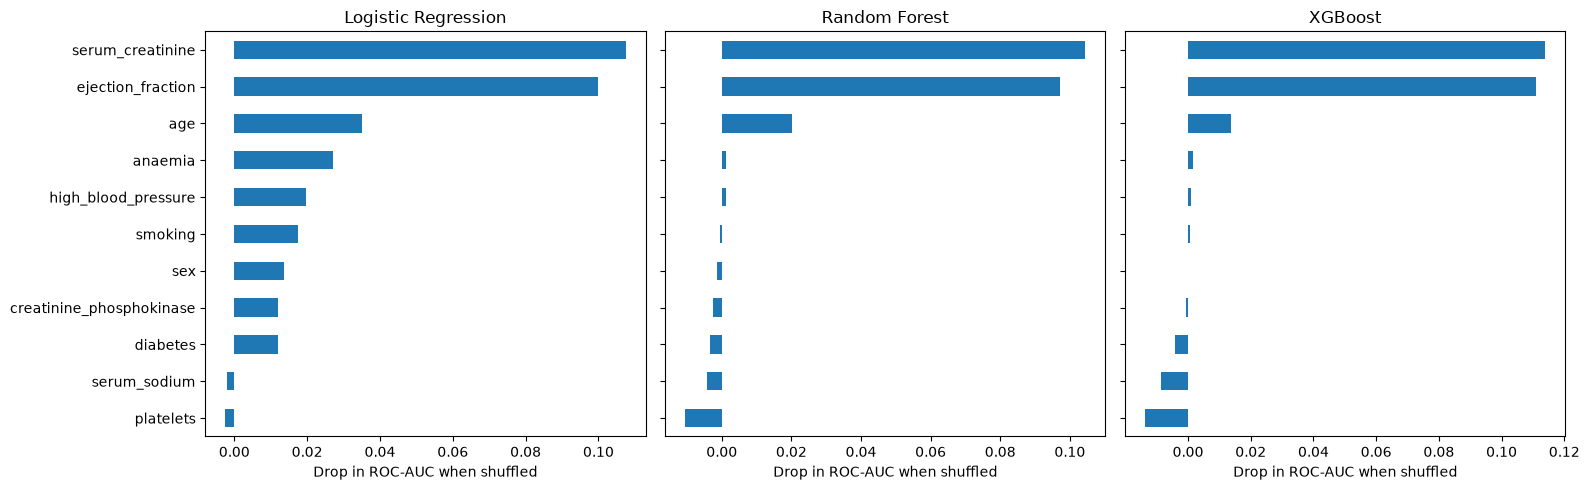

,Logistic Regression,Random Forest,XGBoost,average
time,0.2021,0.2338,0.2569,0.2309
ejection_fraction,0.0684,0.0497,0.0460,0.0547
serum_creatinine,0.0339,0.0489,0.0363,0.0397
creatinine_phosphokinase,0.0075,0.0073,0.0029,0.0059
age,0.0095,0.0014,0.0012,0.0040


,coefficient,odds_ratio_per_1_SD
serum_creatinine,1.089,2.972
ejection_fraction,-0.786,0.456
age,0.480,1.616
anaemia,0.352,1.421
creatinine_phosphokinase,0.349,1.417
high_blood_pressure,0.326,1.386
diabetes,0.290,1.336
smoking,0.225,1.252
serum_sodium,-0.182,0.833
platelets,-0.135,0.874


In [20]:
def cv_permutation_importance(model, cols, n_repeats=5):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    imps = []
    for tr, va in skf.split(X_train, y_train):
        m = clone(model).fit(X_train.iloc[tr][cols], y_train.iloc[tr])
        r = permutation_importance(m, X_train.iloc[va][cols], y_train.iloc[va],
                                   scoring='roc_auc', n_repeats=n_repeats,
                                   random_state=RANDOM_STATE)
        imps.append(r.importances_mean)
    return pd.Series(np.mean(imps, axis=0), index=cols)

MODEL_NAMES = ['Logistic Regression', 'Random Forest', 'XGBoost']
importance = {}
for fs_name, cols in FEATURE_SETS.items():
    importance[fs_name] = pd.DataFrame({
        m_name: cv_permutation_importance(best_models[(fs_name, m_name)], cols)
        for m_name in MODEL_NAMES
    })

# Without time (realistic version)
imp_no_time = importance['without time'].copy()
imp_no_time['average'] = imp_no_time.mean(axis=1)
imp_no_time = imp_no_time.sort_values('average', ascending=False)
display(imp_no_time.round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for a, m_name in zip(ax, MODEL_NAMES):
    imp_no_time[m_name].sort_values().plot.barh(ax=a)
    a.set_title(m_name)
    a.set_xlabel('Drop in ROC-AUC when shuffled')
plt.tight_layout()
plt.show()

# With time: where does it rank?
imp_with_time = importance['with time'].copy()
imp_with_time['average'] = imp_with_time.mean(axis=1)
display(imp_with_time.sort_values('average', ascending=False).round(4).head(5))

# Logistic Regression odds ratios (without time)
lr = clone(best_models[('without time', 'Logistic Regression')]).fit(X_train[NO_TIME], y_train)
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=NO_TIME)
lr_table = pd.DataFrame({'coefficient': coef, 'odds_ratio_per_1_SD': np.exp(coef)})
lr_table.sort_values('coefficient', key=abs, ascending=False).round(3)

## Step 13: Final test on the 60 held-out patients
**Run this cell ONCE, then stop.** Do not change the models or settings after seeing these results. That would turn the test set into more training data and the score would no longer be honest.

Every model was chosen and tuned before this step. Here each one is trained on the full training set (real only, and real + synthetic) and scored on the 60 test patients.
Because 60 patients is small, the accuracy 95% CI column shows how uncertain the accuracy is.

,features,training data,model,accuracy,precision,recall,f1,roc_auc,accuracy 95% CI
0,any,real only,Majority-class baseline,0.683,0.000,0.000,0.000,0.500,
1,with time,real only,Logistic Regression,0.800,0.733,0.579,0.647,0.860,0.70 to 0.90
2,with time,real + synthetic,Logistic Regression,0.800,0.733,0.579,0.647,0.865,0.70 to 0.90
3,with time,real only,Random Forest,0.850,0.812,0.684,0.743,0.899,0.75 to 0.93
4,with time,real + synthetic,Random Forest,0.833,0.800,0.632,0.706,0.900,0.73 to 0.92
5,with time,real only,XGBoost,0.850,0.857,0.632,0.727,0.845,0.75 to 0.93
6,with time,real + synthetic,XGBoost,0.833,0.800,0.632,0.706,0.874,0.73 to 0.92
7,without time,real only,Logistic Regression,0.683,0.500,0.526,0.513,0.734,0.57 to 0.80
8,without time,real + synthetic,Logistic Regression,0.700,0.526,0.526,0.526,0.765,0.58 to 0.82
9,without time,real only,Random Forest,0.717,0.545,0.632,0.585,0.801,0.60 to 0.82


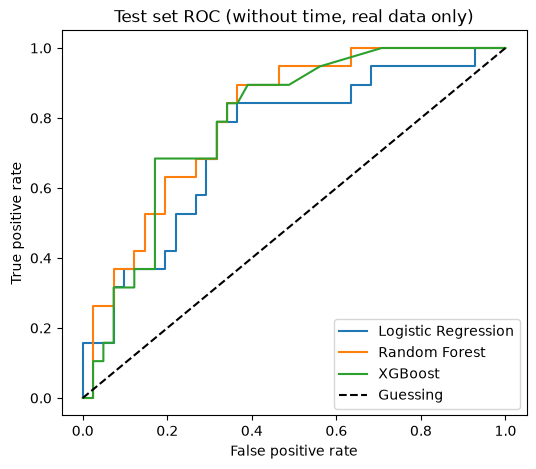

In [21]:
def evaluate_on_test(model, cols, use_synth):
    if use_synth:
        X_syn, y_syn = make_synthetic(X_train, y_train, seed=RANDOM_STATE)
        X_fit = pd.concat([X_train, X_syn], ignore_index=True)
        y_fit = pd.concat([y_train.reset_index(drop=True), y_syn], ignore_index=True)
    else:
        X_fit, y_fit = X_train, y_train
    m = fit_model(model, X_fit, y_fit, cols)
    pred = m.predict(X_test[cols])
    prob = m.predict_proba(X_test[cols])[:, 1]

    rng = np.random.default_rng(RANDOM_STATE)
    correct = (pred == y_test.values)
    boots = [correct[rng.integers(0, len(correct), len(correct))].mean() for _ in range(2000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])

    return {
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, prob),
        'accuracy 95% CI': f"{lo:.2f} to {hi:.2f}",
    }, prob

final_rows, final_probs = [], {}

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
d_pred = dummy.predict(X_test)
final_rows.append({'features': 'any', 'training data': 'real only', 'model': 'Majority-class baseline',
                   'accuracy': accuracy_score(y_test, d_pred),
                   'precision': precision_score(y_test, d_pred, zero_division=0),
                   'recall': recall_score(y_test, d_pred), 'f1': f1_score(y_test, d_pred),
                   'roc_auc': 0.5, 'accuracy 95% CI': ''})

for (fs_name, m_name), model in best_models.items():
    for use_synth in (False, True):
        metrics, prob = evaluate_on_test(model, FEATURE_SETS[fs_name], use_synth)
        label = 'real + synthetic' if use_synth else 'real only'
        final_rows.append({'features': fs_name, 'training data': label, 'model': m_name, **metrics})
        final_probs[(fs_name, label, m_name)] = prob

final_table = pd.DataFrame(final_rows)
num_cols = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
final_table[num_cols] = final_table[num_cols].round(3)
display(final_table)

plt.figure(figsize=(6, 5))
for m_name in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_test, final_probs[('without time', 'real only', m_name)])
    plt.plot(fpr, tpr, label=m_name)
plt.plot([0, 1], [0, 1], 'k--', label='Guessing')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Test set ROC (without time, real data only)')
plt.legend()
plt.show()

## Wrap up
- **Baseline:** guessing "survived" gives ~68% accuracy and catches no deaths.
- **With `time`:** Best model was Random Forest with an accuracy of 0.842+- 0.040. This is an upper limit because `time` is not known when predicting for a new patient.
- **Without `time` (realistic):** Best model was Random Forest with an accuracy of 0.747 +- 0.047. None of the models without time hit 80%
- **Tuning:** Best model with `time` was Random Forest with an accuracy of 0.841 +- 0.043. Close second was XGBoost 0.840 +- 0.047. Best model without `time` was Random Forest with an accuracy of 0.763 +- 0.049. It's safe to say that the tuning didn't really change much. Without `time` is still under 80%.
- **Synthetic data:** The accuracy's between real-only and real+synthetic are very similar.
- **Most important features:** The top 3 important features according to our plots (Logistic Regression, Random Forest, XGBoost) are `serum_creatinine`, `ejection_fraction`, and `age`.
- **Limits:** only 299 real patients, one study, and a 60-patient test set gives a wide range of possible accuracy (see the 95% CI). Not ready for clinical use.

## Conclusion

- This project explored whether machine learning could predict survival in patients with heart failure using clinical variables such as age, kidney function, and heart pumping ability. The results suggest that prediction is possible, but the performance depends heavily on the information available. The baseline model, which simply guessed that patients survived, achieved about 68% accuracy, showing that the dataset is imbalanced and that simple prediction is not enough. When time-related variables were included, Random Forest performed best, reaching approximately 84% accuracy, which indicates that adding richer clinical information can improve predictive power. However, this is not a realistic setting for predicting the outcome of a new patient, because time-related values are not known in advance. In the more realistic scenario without time, the best model was still Random Forest, with accuracy around 75%, which is better than baseline but still below the level needed for confident clinical decision-making.

- Across all model comparisons, tuning did not substantially improve performance, suggesting that the main challenge is not only model selection but also the limitations of the dataset itself. The most important predictors were serum creatinine, ejection fraction, and age, which are clinically meaningful and align with medical understanding of heart failure risk. This strengthens the interpretability of the models and suggests that the models are learning real risk signals rather than noise. Synthetic data did not meaningfully improve performance, indicating that the added data did not contain much additional predictive value and that data quality and representativeness are more important than dataset size alone.

- Overall, the notebook demonstrates that machine learning can identify patterns associated with survival in heart failure patients, but the study remains limited by its sample size, single-study design, and small test set. These limitations produce uncertainty in the reported accuracy and mean the models are not yet ready for clinical use. Future work should focus on larger, multi-center datasets, external validation, and stronger clinical evaluation before these models could be considered for real-world medical decision support.

